# 🗂️ Importing the datasets

In [ ]:
import zipfile
import os
import io
import pandas as pd
import numpy as np
import seaborn as sns
import re
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from umap import UMAP
import warnings
import random
!pip install mplfinance
import mplfinance as mpf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 2.8 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_name_to_find_1 = 'ERC20-stablecoins.zip'
found_paths_1 = []

# Assuming Google Drive is mounted at /content/drive/
# Adjust this path if your Google Drive is mounted elsewhere
drive_path = '/content/drive/'

print(f"Searching for '{file_name_to_find_1}' in {drive_path}...")

for root, dirs, files in os.walk(drive_path):
    if file_name_to_find_1 in files:
        found_paths_1.append(os.path.join(root, file_name_to_find_1))

if found_paths_1:
    print(f"Found '{file_name_to_find_1}' at the following location(s):")
    for path in found_paths_1:
        print(path)
else:
    print(f"'{file_name_to_find_1}' not found in Google Drive.")

Searching for 'ERC20-stablecoins.zip' in /content/drive/...
Found 'ERC20-stablecoins.zip' at the following location(s):
/content/drive/MyDrive/Databusters 2026/Code/ERC20-stablecoins.zip


In [ ]:
print("Files in ERC20-stablecoins.zip:")
print("=" * 50)

# Dynamically set the zip file path using the found_paths variable
if found_paths_1:
    zip_file_path_1 = found_paths_1[0] # Assuming the first found path is the correct one
    print(f"Using zip file from: {zip_file_path_1}")
else:
    print("Error: 'ERC20-stablecoins.zip' was not found in Google Drive. Please ensure it's mounted and accessible.")
    # Exit or handle the error appropriately if the file is not found
    # For now, let's assume it's found based on previous execution
    zip_file_path_1 = None # Or raise an error

if zip_file_path_1:
    with zipfile.ZipFile(zip_file_path_1, "r") as outer_zip:
        for name in outer_zip.namelist():
            if name.endswith(".csv"):
                print(f"📄 {name}")
            elif name.endswith(".zip"):
                print(f"📦 {name}")
                nested_zip_data = outer_zip.read(name)
                with zipfile.ZipFile(io.BytesIO(nested_zip_data), "r") as inner_zip:
                    for inner_name in inner_zip.namelist():
                        if inner_name.endswith(".csv"):
                            print(f"  📄 {inner_name}")

Files in ERC20-stablecoins.zip:
Using zip file from: /content/drive/MyDrive/Databusters 2026/Code/ERC20-stablecoins.zip
📄 token_transfers.csv
📄 token_transfers_V2.0.0.csv
📄 token_transfers_V3.0.0.csv
📦 price_data.zip
  📄 price_data/dai_price_data.csv
  📄 price_data/pax_price_data.csv
  📄 price_data/usdc_price_data.csv
  📄 price_data/usdt_price_data.csv
  📄 price_data/ustc_price_data.csv
  📄 price_data/wluna_price_data.csv
📄 event_data.csv


In [ ]:
file_name_to_find_2 = 'gfc.zip'
found_paths_2 = []

# Assuming Google Drive is mounted at /content/drive/
# Adjust this path if your Google Drive is mounted elsewhere
drive_path = '/content/drive/'

print(f"Searching for '{file_name_to_find_2}' in {drive_path}...")

for root, dirs, files in os.walk(drive_path):
    if file_name_to_find_2 in files:
        found_paths_2.append(os.path.join(root, file_name_to_find_2))

if found_paths_2:
    print(f"Found '{file_name_to_find_2}' at the following location(s):")
    for path in found_paths_2:
        print(path)
else:
    print(f"'{file_name_to_find_2}' not found in Google Drive.")


print("Files in :gfc.zip")
print("=" * 50)

# Dynamically set the zip file path using the found_paths variable
if found_paths_2:
    zip_file_path_2 = found_paths_2[0] # Assuming the first found path is the correct one
    print(f"Using zip file from: {zip_file_path_2}")
else:
    print("Error: 'gfc.zip' was not found in Google Drive. Please ensure it's mounted and accessible.")
    # Exit or handle the error appropriately if the file is not found
    # For now, let's assume it's found based on previous execution
    zip_file_path_2 = None # Or raise an error

if zip_file_path_2:
    with zipfile.ZipFile(zip_file_path_2, "r") as outer_zip:
        for name in outer_zip.namelist():
            if name.endswith(".csv"):
                print(f"📄 {name}")
            elif name.endswith(".zip"):
                print(f"📦 {name}")
                nested_zip_data = outer_zip.read(name)
                with zipfile.ZipFile(io.BytesIO(nested_zip_data), "r") as inner_zip:
                    for inner_name in inner_zip.namelist():
                        if inner_name.endswith(".csv"):
                            print(f"  📄 {inner_name}")

Searching for 'gfc.zip' in /content/drive/...
Found 'gfc.zip' at the following location(s):
/content/drive/MyDrive/Databusters 2026/Code/gfc.zip
Files in :gfc.zip
Using zip file from: /content/drive/MyDrive/Databusters 2026/Code/gfc.zip
📄 gfc data/AIG.csv
📄 gfc data/^VIX.csv
📄 gfc data/C.csv
📄 gfc data/JPM.csv
📄 gfc data/^GSPC.csv
📄 gfc data/WGS3MO.csv
📄 gfc data/^DJI.csv
📄 gfc data/TEDRATE.csv


## 📄 Data Cleaning and Formatting

In [ ]:
WANTED = [
  "price_data/dai_price_data.csv",
  "price_data/pax_price_data.csv",
  "price_data/usdc_price_data.csv",
  "price_data/usdt_price_data.csv",
  "price_data/ustc_price_data.csv",
  "price_data/wluna_price_data.csv",
  "event_data.csv",

]
def clean_name(path):
    name = path.split("/")[-1]
    name = name.replace(".csv", "")
    name = re.sub(r"[^\w]", "_", name)
    return name
def convert_timestamp(df):
    if "timestamp" in df.columns:
        df["datetime"] = pd.to_datetime(df["timestamp"], unit="s")
    return df

with zipfile.ZipFile(zip_file_path_1, "r") as outer_zip:

    for name in outer_zip.namelist():

        if name.endswith(".csv"):
            # Only load if the CSV is in the WANTED list
            if name not in WANTED:
                continue

            var_name = clean_name(name)

            with outer_zip.open(name) as f:
                df = pd.read_csv(f, encoding='latin1') # Added encoding

            df = convert_timestamp(df)

            globals()[var_name] = df
            print(f"Loaded → {var_name}  | timestamp converted")

        elif name.endswith(".zip"):
            nested_data = outer_zip.read(name)

            with zipfile.ZipFile(io.BytesIO(nested_data), "r") as inner_zip:

                for inner_name in inner_zip.namelist():

                    # Only load if the inner CSV is in the WANTED list
                    if inner_name not in WANTED:
                        continue

                    var_name = clean_name(inner_name)

                    with inner_zip.open(inner_name) as f:
                        df = pd.read_csv(f, encoding='latin1') # Added encoding

                    df = convert_timestamp(df)

                    globals()[var_name] = df
                    print(f"Loaded → {var_name}  | timestamp converted")
#print (dai_price_data.head())


Loaded → dai_price_data  | timestamp converted
Loaded → pax_price_data  | timestamp converted
Loaded → usdc_price_data  | timestamp converted
Loaded → usdt_price_data  | timestamp converted
Loaded → ustc_price_data  | timestamp converted
Loaded → wluna_price_data  | timestamp converted
Loaded → event_data  | timestamp converted


In [ ]:
WANTED = [
    "gfc data/AIG.csv",
    "gfc data/^VIX.csv",
    "gfc data/C.csv",
    "gfc data/JPM.csv",
    "gfc data/^GSPC.csv",
    "gfc data/WGS3MO.csv",
    "gfc data/^DJI.csv",
    "gfc data/TEDRATE.csv"
]

def clean_name(path):
    name = path.split("/")[-1]
    name = name.replace(".csv", "")
    name = re.sub(r"[^\w]", "_", name)
    return name

START_DATE = "2006-01-01"
END_DATE   = "2009-12-31"

with zipfile.ZipFile(zip_file_path_2, "r") as outer_zip:

    for name in outer_zip.namelist():

        if name.endswith(".csv"):
            if name not in WANTED:
                continue

            var_name = clean_name(name)

            with outer_zip.open(name) as f:
                df = pd.read_csv(
                    f,
                    header=0,
                    skiprows=[1, 2],
                    encoding="latin1"
                )

                # rename first column to Date
                df.rename(columns={df.columns[0]: "Date"}, inplace=True)

                # convert to datetime
                df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

                # filter 2006–2009
                df = df[(df["Date"] >= START_DATE) & (df["Date"] <= END_DATE)]

                globals()[var_name] = df

            print(f"Loaded → {var_name}")

        elif name.endswith(".zip"):
            nested_data = outer_zip.read(name)

            with zipfile.ZipFile(io.BytesIO(nested_data), "r") as inner_zip:

                for inner_name in inner_zip.namelist():
                    if inner_name not in WANTED:
                        continue

                    var_name = clean_name(inner_name)

                    with inner_zip.open(inner_name) as f:
                        df = pd.read_csv(
                            f,
                            header=0,
                            skiprows=[1, 2],
                            encoding="latin1"
                        )

                        df.rename(columns={df.columns[0]: "Date"}, inplace=True)
                        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
                        df = df[(df["Date"] >= START_DATE) & (df["Date"] <= END_DATE)]

                        globals()[var_name] = df

                    print(f"Loaded → {var_name}")

print(AIG.head())

Loaded → AIG
Loaded → _VIX
Loaded → C
Loaded → JPM
Loaded → _GSPC
Loaded → WGS3MO
Loaded → _DJI
Loaded → TEDRATE
          Date       Close        High         Low        Open  Volume
252 2006-01-03  839.945068  840.427613  806.405192  831.741081  438190
253 2006-01-04  841.151794  848.752549  835.601982  841.996339  309935
254 2006-01-05  842.237122  845.132681  837.652548  843.322975  197095
255 2006-01-06  845.856873  847.787271  837.290957  844.529784  287175
256 2006-01-09  841.875610  844.409244  839.342050  842.720155  292405


In [ ]:
df = pd.read_csv("/content/token_transfers.csv", sep=",")


In [ ]:
def convert_timestamp(df):
    if "time_stamp" in df.columns:
        df["time_stamp"] = pd.to_datetime(df["time_stamp"], unit="s")
    return df

df = convert_timestamp (df)

manual_mapping = {
    "0x6b175474e89094c44da98b954eedeac495271d0f": "DAI",
    "0x8e870d67f660d95d5be530380d0ec0bd388289e1": "PAX",
    "0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48": "USDC",
    "0xdac17f958d2ee523a2206206994597c13d831ec7": "USDT",
    "0xa47c8bf37f92abed4a126bda807a7b7498661acd": "USTC",
    "0xd2877702675e6ceb975b4a1dff9fb7baf4c91ea9": "WLUNA"
}
df["token"] = df["contract_address"].map(manual_mapping)
df = df.drop(columns=["contract_address"])

cutoff = pd.Timestamp("2022-06-02")

df = df[df["time_stamp"] <= cutoff]

print(df["time_stamp"].min(), df["time_stamp"].max())

globals()["token_transfer"]=df
print(token_transfer.head())

2022-04-28 00:30:15 2022-04-29 17:18:17
   block_number  transaction_index  \
0      14669683                  7   
1      14669683                 45   
2      14669683                 46   
3      14669683                 47   
4      14669683                 48   

                                 from_address  \
0  0xd30b438df65f4f788563b2b3611bd6059bff4ad9   
1  0x4941834ed1428089ee76252f6f9d767e800499b0   
2  0x2c1f9a20711e14f8484a41123e20d1b06858ebea   
3  0x7784c4f53aa5f03bd6d3ca670c9d9c887cc38cb0   
4  0x66589b8278470d58d4112f3d065de0f75734312e   

                                   to_address          time_stamp  \
0  0xda816e2122a8a39b0926bfa84edd3d42477e9efd 2022-04-28 00:30:15   
1  0x28c6c06298d514db089934071355e5743bf21d60 2022-04-28 00:30:15   
2  0x28c6c06298d514db089934071355e5743bf21d60 2022-04-28 00:30:15   
3  0x3cd751e6b0078be393132286c442345e5dc49699 2022-04-28 00:30:15   
4  0x28c6c06298d514db089934071355e5743bf21d60 2022-04-28 00:30:15   

          value token

# Data Visualisation

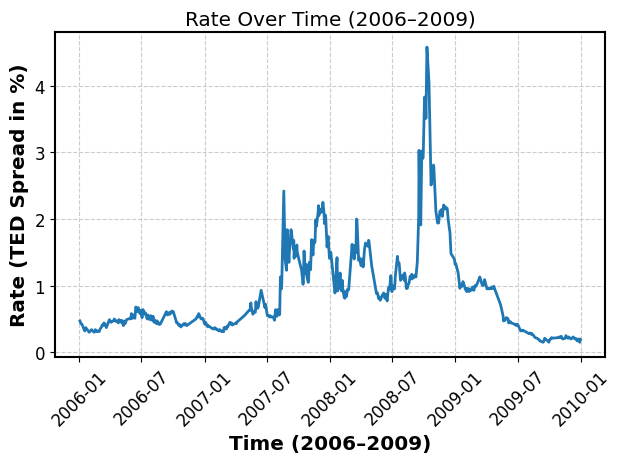

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mplfinance.original_flavor import candlestick_ohlc
import mplfinance as mpf


# Read the CSV file (assumes first column = date, second = rate)
df = TEDRATE.copy()

# Rename columns for clarity (optional but recommended)
df.columns = ["date", "rate"]

# --- Convert date column to datetime ---
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# --- Drop rows with missing dates or missing rates ---
df = df.dropna(subset=["date", "rate"])

# --- Filter data from 2006 to 2009 ---
df_filtered = df[
    (df["date"].dt.year >= 2006) &
    (df["date"].dt.year <= 2009)
]

# --- Plot ---
plt.figure()
plt.plot(df_filtered["date"], df_filtered["rate"])
plt.xlabel("Time (2006–2009)")
plt.ylabel("Rate (TED Spread in %)") # Higher percentage means banks perceive higher credit risk; acts as a "risk gause".
plt.title("Rate Over Time (2006–2009)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## MMFs (2022)

TerraUSD and WLUNA: Price Analysis

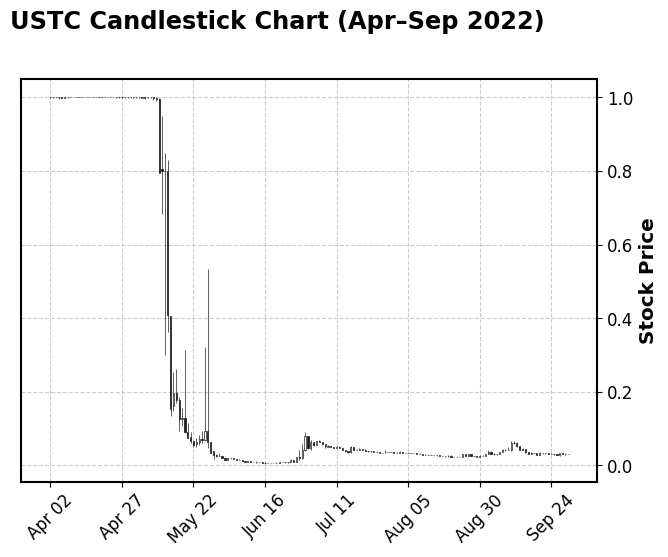

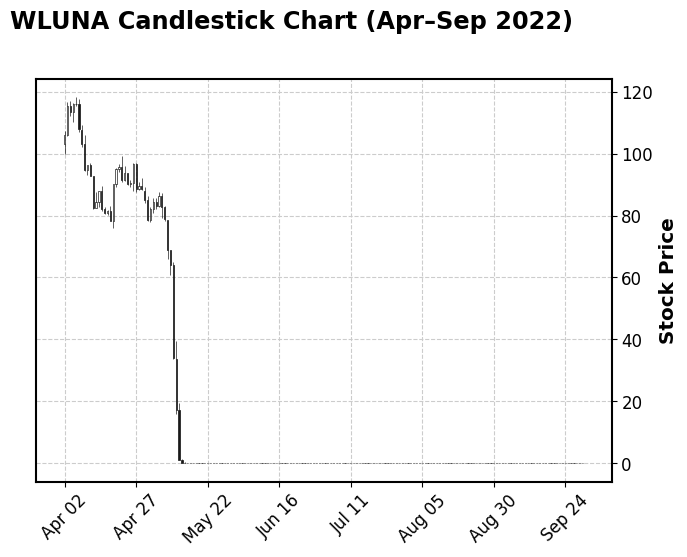

In [ ]:
##### USTC (TerraUSD) #####

# Load CSV
df = ustc_price_data.copy()

# Convert datetime column
df.loc[:, 'datetime'] = pd.to_datetime(
    df.loc[:, 'datetime'],
    format='%Y-%m-%d'
)

# Set datetime as index (x-axis)
df.set_index('datetime', inplace=True)

# Rename columns to mplfinance standard
df = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Zoom into April–September 2022
df_zoom = df.loc['2022-04-01':'2022-09-30']

# Plot candlestick chart
mpf.plot(
    df_zoom,
    type='candle',
    style='classic',
    title='USTC Candlestick Chart (Apr–Sep 2022)',
    ylabel='Stock Price'
)

##### WLUNA #####

# Load CSV
df = wluna_price_data.copy()

# Convert datetime column
df.loc[:, 'datetime'] = pd.to_datetime(
    df.loc[:, 'datetime'],
    format='%Y-%m-%d'
)

# Set datetime as index (x-axis)
df.set_index('datetime', inplace=True)

# Rename columns to mplfinance standard
df = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Zoom into –September 2022
df_zoom = df.loc['2022-04-01':'2022-09-30']

# Plot candlestick chart
mpf.plot(
    df_zoom,
    type='candle',
    style='classic',
    title='WLUNA Candlestick Chart (Apr–Sep 2022)',
    ylabel='Stock Price'
)


Other Stablecoins

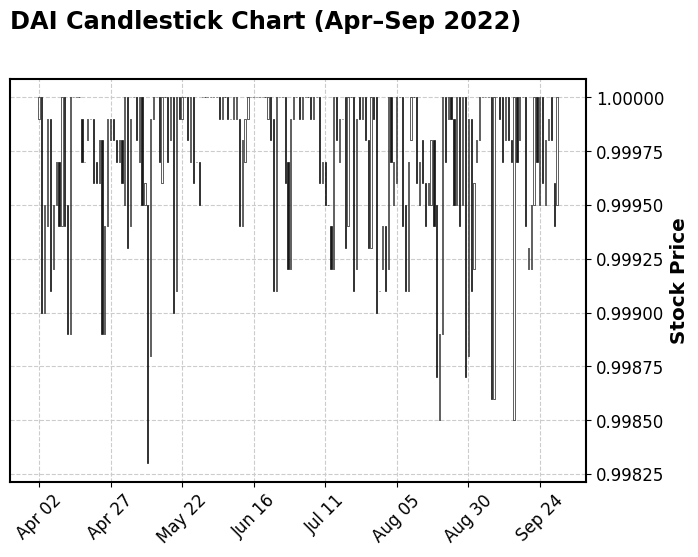

In [ ]:
##### DAI #####

# Load CSV
df = dai_price_data.copy()

# Convert datetime column
df.loc[:, 'datetime'] = pd.to_datetime(
    df.loc[:, 'datetime'],
    format='%Y-%m-%d'
)

# Set datetime as index (x-axis)
df.set_index('datetime', inplace=True)

# Rename columns to mplfinance standard
df = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Zoom into April–September 2022
df_zoom = df.loc['2022-04-01':'2022-09-30']

# Plot candlestick chart
mpf.plot(
    df_zoom,
    type='candle',
    style='classic',
    title='DAI Candlestick Chart (Apr–Sep 2022)',
    ylabel='Stock Price',
    xrotation=45
)


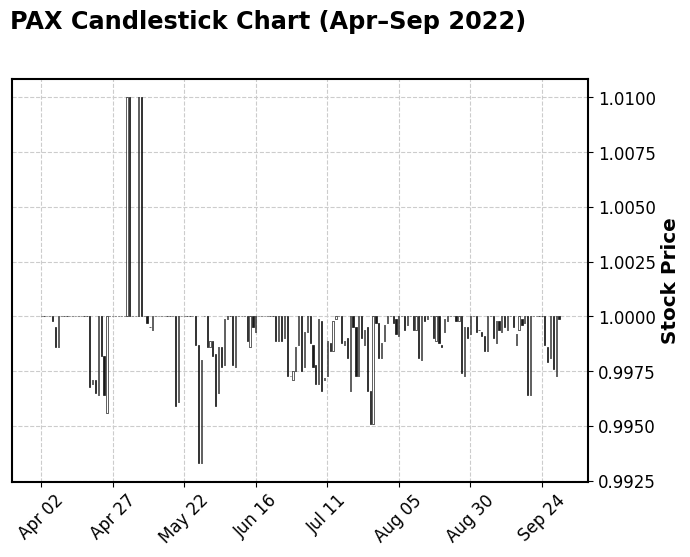

In [ ]:
##### PAX #####

# Load CSV
df = pax_price_data.copy()

# Convert datetime column
df.loc[:, 'datetime'] = pd.to_datetime(
    df.loc[:, 'datetime'],
    format='%Y-%m-%d'
)

# Set datetime as index (x-axis)
df.set_index('datetime', inplace=True)

# Rename columns to mplfinance standard
df = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Zoom into April–September 2022
df_zoom = df.loc['2022-04-01':'2022-09-30']

# Plot candlestick chart
mpf.plot(
    df_zoom,
    type='candle',
    style='classic',
    title='PAX Candlestick Chart (Apr–Sep 2022)',
    ylabel='Stock Price',
    xrotation=45
)

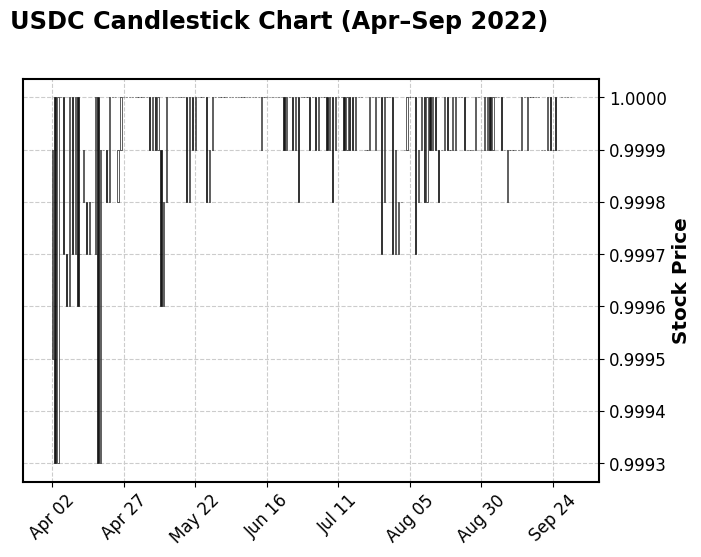

In [ ]:
##### USDC #####

# Load CSV
df = usdc_price_data.copy()

# Convert datetime column
df.loc[:, 'datetime'] = pd.to_datetime(
    df.loc[:, 'datetime'],
    format='%Y-%m-%d'
)

# Set datetime as index (x-axis)
df.set_index('datetime', inplace=True)

# Rename columns to mplfinance standard
df = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Zoom into April–September 2022
df_zoom = df.loc['2022-04-01':'2022-09-30']

# Plot candlestick chart
mpf.plot(
    df_zoom,
    type='candle',
    style='classic',
    title='USDC Candlestick Chart (Apr–Sep 2022)',
    ylabel='Stock Price',
    xrotation=45
)

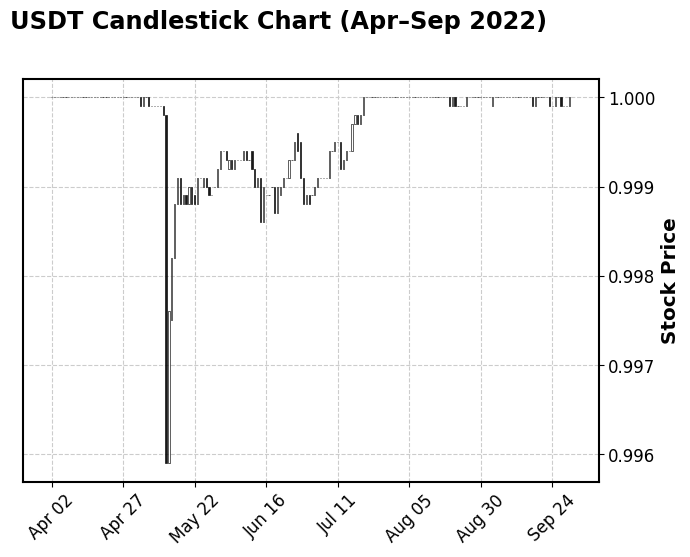

In [ ]:
##### USDT #####

# Load CSV
df = usdt_price_data.copy()

# Convert datetime column
df.loc[:, 'datetime'] = pd.to_datetime(
    df.loc[:, 'datetime'],
    format='%Y-%m-%d'
)

# Set datetime as index (x-axis)
df.set_index('datetime', inplace=True)

# Rename columns to mplfinance standard
df = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Zoom into April–September 2022
df_zoom = df.loc['2022-04-01':'2022-09-30']

# Plot candlestick chart
mpf.plot(
    df_zoom,
    type='candle',
    style='classic',
    title='USDT Candlestick Chart (Apr–Sep 2022)',
    ylabel='Stock Price',
    xrotation=45
)

<Figure size 640x480 with 0 Axes>

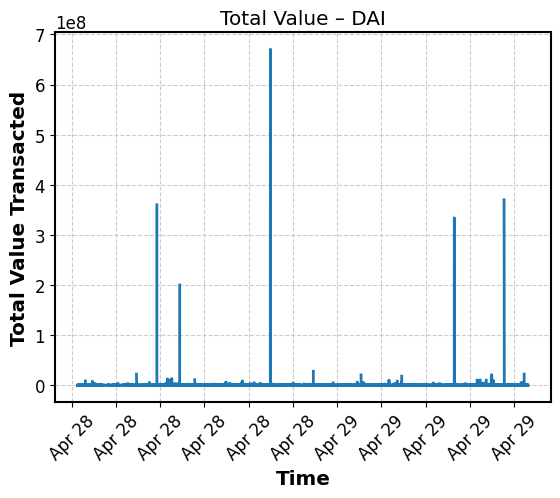

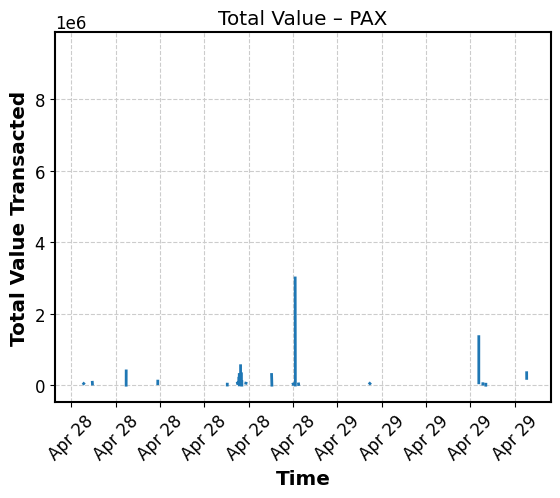

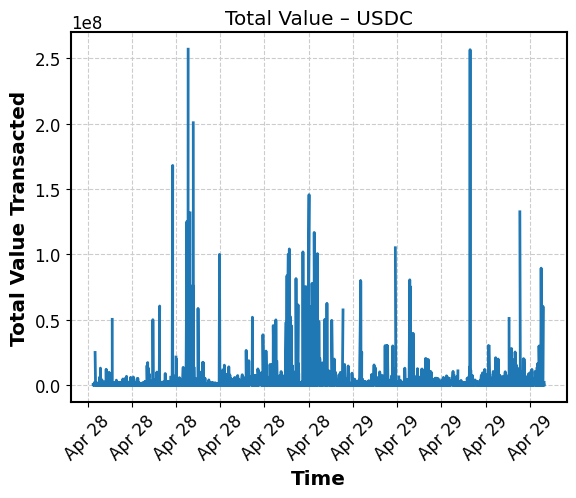

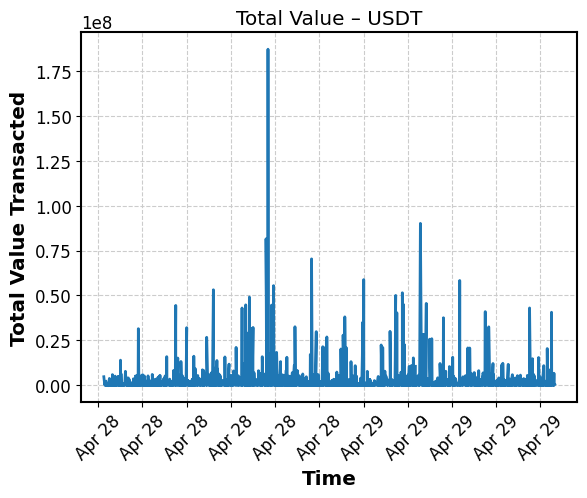

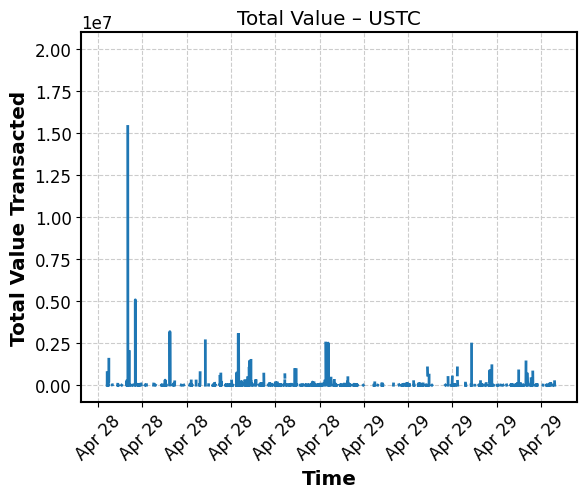

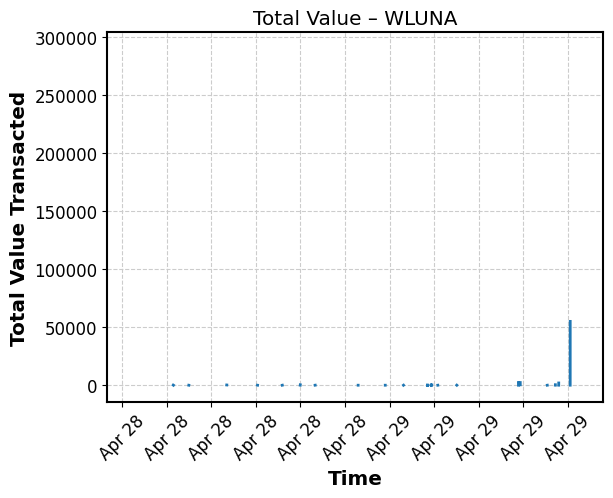

In [ ]:
df = token_transfer.copy()

# 1. Aggregate total value by time and token
grouped = (
    df.groupby(["time_stamp", "token"])["value"]
      .sum()
      .reset_index()
)

# 2. Pivot so each token becomes one column = one line
pivot = grouped.pivot(
    index="time_stamp",
    columns="token",
    values="value"
)

# 3. Plot
plt.figure()

for token in pivot.columns:
    plt.figure()  # new figure each time
    plt.plot(pivot.index, pivot[token])
    plt.xticks(rotation=45)
    plt.xlabel("Time")
    plt.ylabel("Total Value Transacted")
    plt.title(f"Total Value – {token}")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    plt.show()

## Financial Crisis (2008)

/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


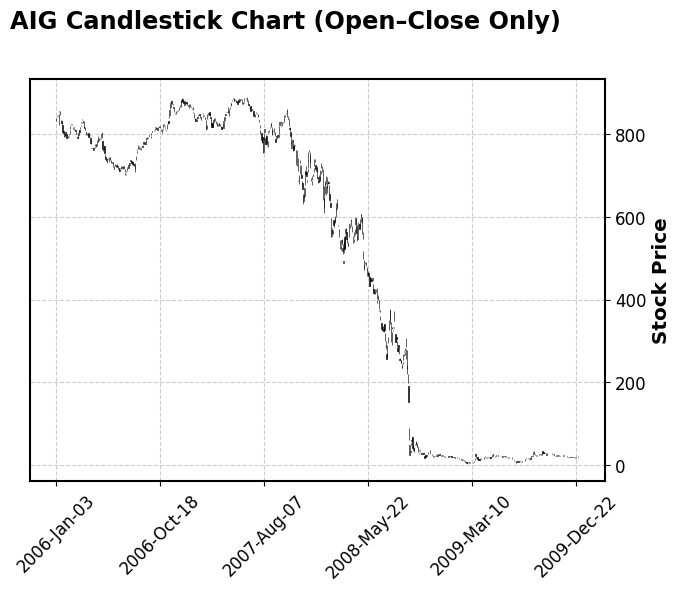

In [ ]:
# Load CSV
df = AIG.copy()

# Set the 'Date' column as the DataFrame's index
df.set_index('Date', inplace=True)

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Plot candlestick chart
mpf.plot(
    df,
    type='candle',
    style='classic',
    title='AIG Candlestick Chart (Open–Close Only)',
    ylabel='Stock Price'
)

/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


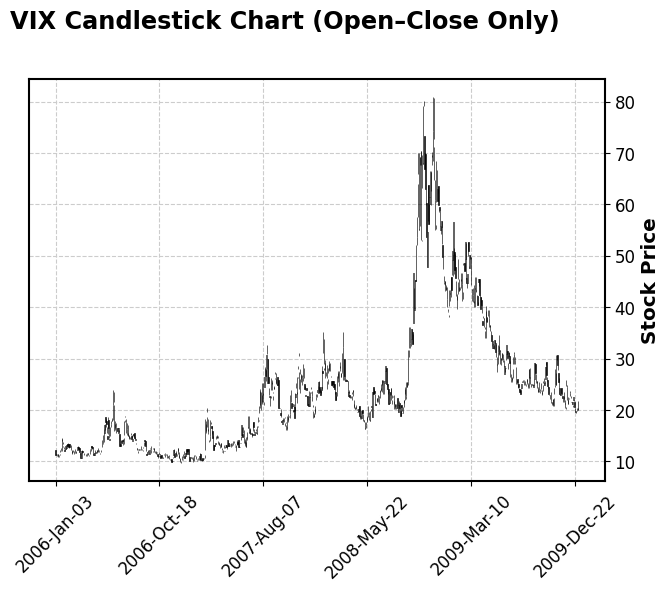

In [ ]:
# Load CSV
df = _VIX.copy()

# Set the 'Date' column as the DataFrame's index
df.set_index('Date', inplace=True)

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Plot candlestick chart
mpf.plot(
    df,
    type='candle',
    style='classic',
    title='VIX Candlestick Chart (Open–Close Only)',
    ylabel='Stock Price'
)

/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


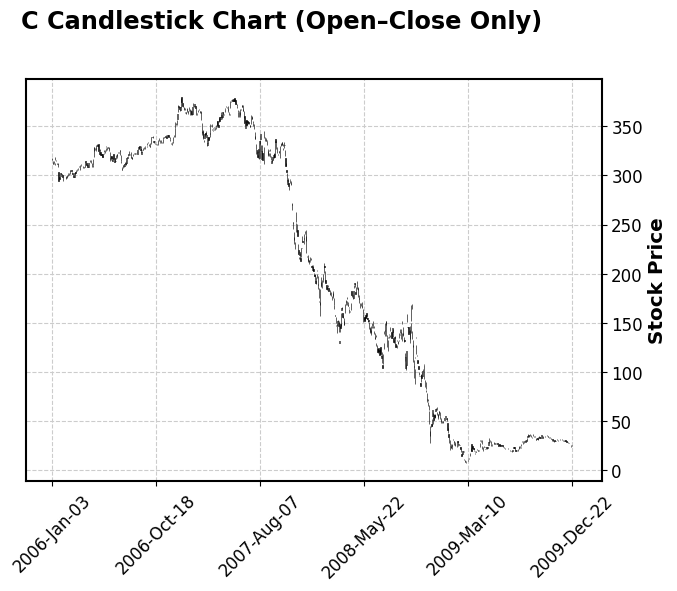

In [ ]:
# Load CSV
df = C.copy()

# Set the 'Date' column as the DataFrame's index
df.set_index('Date', inplace=True)

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Plot candlestick chart
mpf.plot(
    df,
    type='candle',
    style='classic',
    title='C Candlestick Chart (Open–Close Only)',
    ylabel='Stock Price'
)

/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


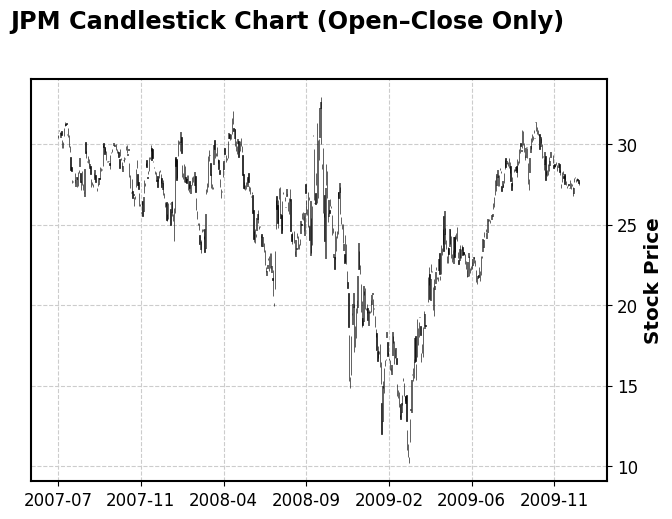

In [ ]:
import mplfinance as mpf

# Load CSV
df = JPM.copy()

# Set the 'Date' column as the DataFrame's index
df.set_index('Date', inplace=True)

# ===== DATE FILTER =====
df = df[df.index >= "2007-07-01"]


# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

mpf.plot(
    df,
    type='candle',
    style='classic',
    title='JPM Candlestick Chart (Open–Close Only)',
    ylabel='Stock Price',
    xrotation=0,
    datetime_format='%Y-%m'
)

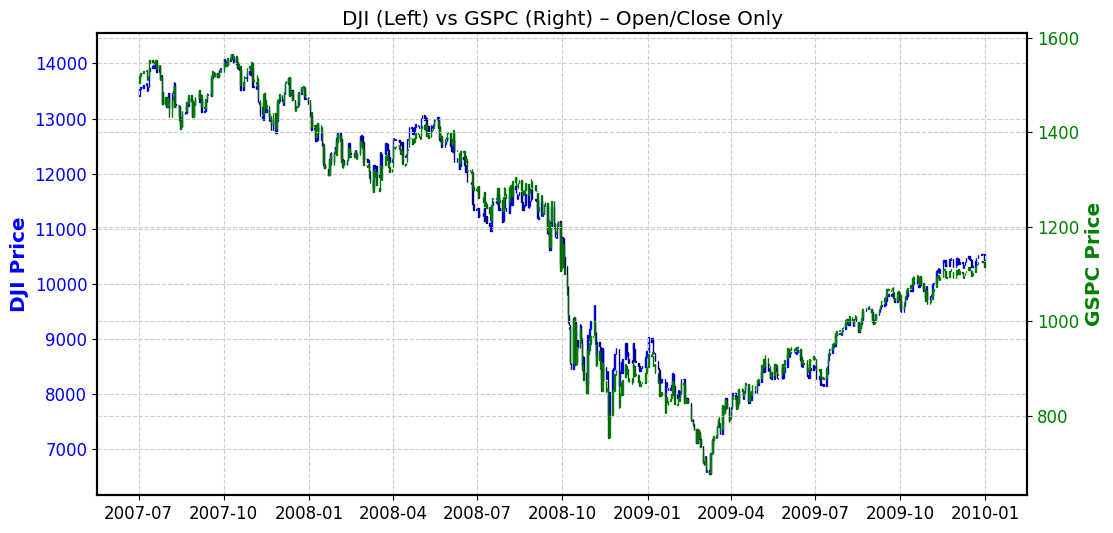

In [ ]:
# ===== PREPARE GSPC =====
gspc = _GSPC.copy()
gspc.set_index('Date', inplace=True)

gspc['High'] = gspc[['Open', 'Close']].max(axis=1)
gspc['Low']  = gspc[['Open', 'Close']].min(axis=1)

gspc.reset_index(inplace=True)
gspc['Date'] = pd.to_datetime(gspc['Date'])
gspc['DateNum'] = mdates.date2num(gspc['Date'])




# ===== PREPARE DJI =====
dji = _DJI.copy()
dji.set_index('Date', inplace=True)

dji['High'] = dji[['Open', 'Close']].max(axis=1)
dji['Low']  = dji[['Open', 'Close']].min(axis=1)

dji.reset_index(inplace=True)
dji['Date'] = pd.to_datetime(dji['Date'])
dji['DateNum'] = mdates.date2num(dji['Date'])

start_date = "2007-07-01"
dji = dji[dji['Date'] >= start_date]
gspc = gspc[gspc['Date'] >= start_date]


dji_ohlc = dji[['DateNum', 'Open', 'High', 'Low', 'Close']]
gspc_ohlc = gspc[['DateNum', 'Open', 'High', 'Low', 'Close']]


fig, ax1 = plt.subplots(figsize=(12, 6))

# ----- LEFT AXIS = DJI -----
candlestick_ohlc(
    ax1,
    dji_ohlc.values,
    width=0.6,
    colorup='blue',
    colordown='navy'
)

ax1.set_ylabel("DJI Price", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')


# ----- RIGHT AXIS = GSPC -----
ax2 = ax1.twinx()

candlestick_ohlc(
    ax2,
    gspc_ohlc.values,
    width=0.6,
    colorup='green',
    colordown='darkgreen'
)

ax2.set_ylabel("GSPC Price", color='green')
ax2.tick_params(axis='y', labelcolor='green')


# ----- Shared X settings -----
ax1.xaxis_date()
ax1.set_title("DJI (Left) vs GSPC (Right) – Open/Close Only")

plt.show()


/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


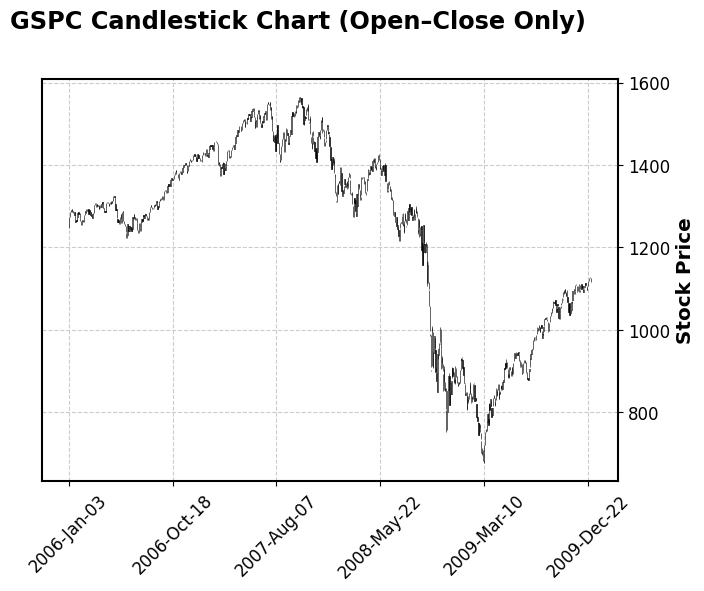

In [ ]:
# Load CSV
df = _GSPC.copy()

# Set the 'Date' column as the DataFrame's index
df.set_index('Date', inplace=True)

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Plot candlestick chart
mpf.plot(
    df,
    type='candle',
    style='classic',
    title='GSPC Candlestick Chart (Open–Close Only)',
    ylabel='Stock Price'
)

/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


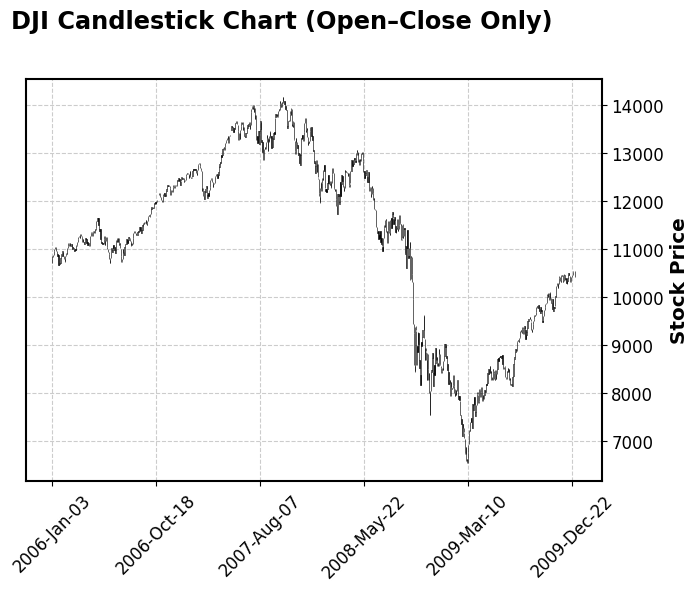

In [ ]:
# Load CSV
df = _DJI.copy()

# Set the 'Date' column as the DataFrame's index
df.set_index('Date', inplace=True)

# Keep ONLY open & close (remove wicks)
df.loc[:, 'High'] = df.loc[:, ['Open', 'Close']].max(axis=1)
df.loc[:, 'Low']  = df.loc[:, ['Open', 'Close']].min(axis=1)

# Plot candlestick chart
mpf.plot(
    df,
    type='candle',
    style='classic',
    title='DJI Candlestick Chart (Open–Close Only)',
    ylabel='Stock Price'
)

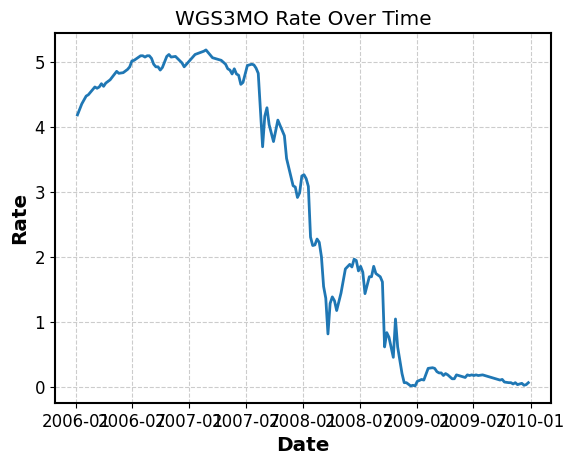

In [ ]:
df = WGS3MO.copy()

df.columns = ["date", "rate"]

df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

df.set_index("date", inplace=True)

plt.figure()
plt.plot(df.index, df["rate"])
plt.xlabel("Date")
plt.ylabel("Rate")
plt.title("WGS3MO Rate Over Time")
plt.show()

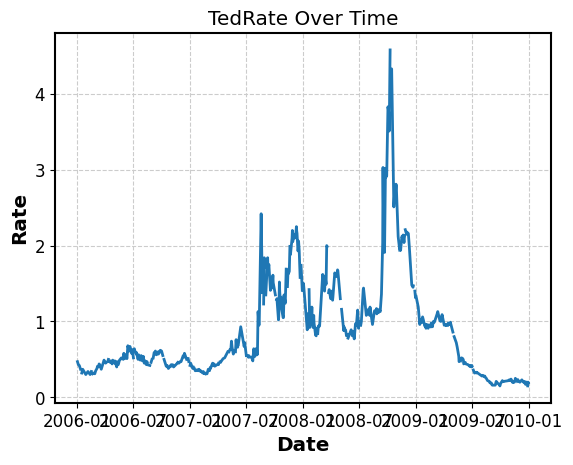

In [ ]:
df = TEDRATE.copy()

df.columns = ["date", "rate"]

df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

df.set_index("date", inplace=True)

plt.figure()
plt.plot(df.index, df["rate"])
plt.xlabel("Date")
plt.ylabel("Rate")
plt.title("TedRate Over Time")
plt.show()

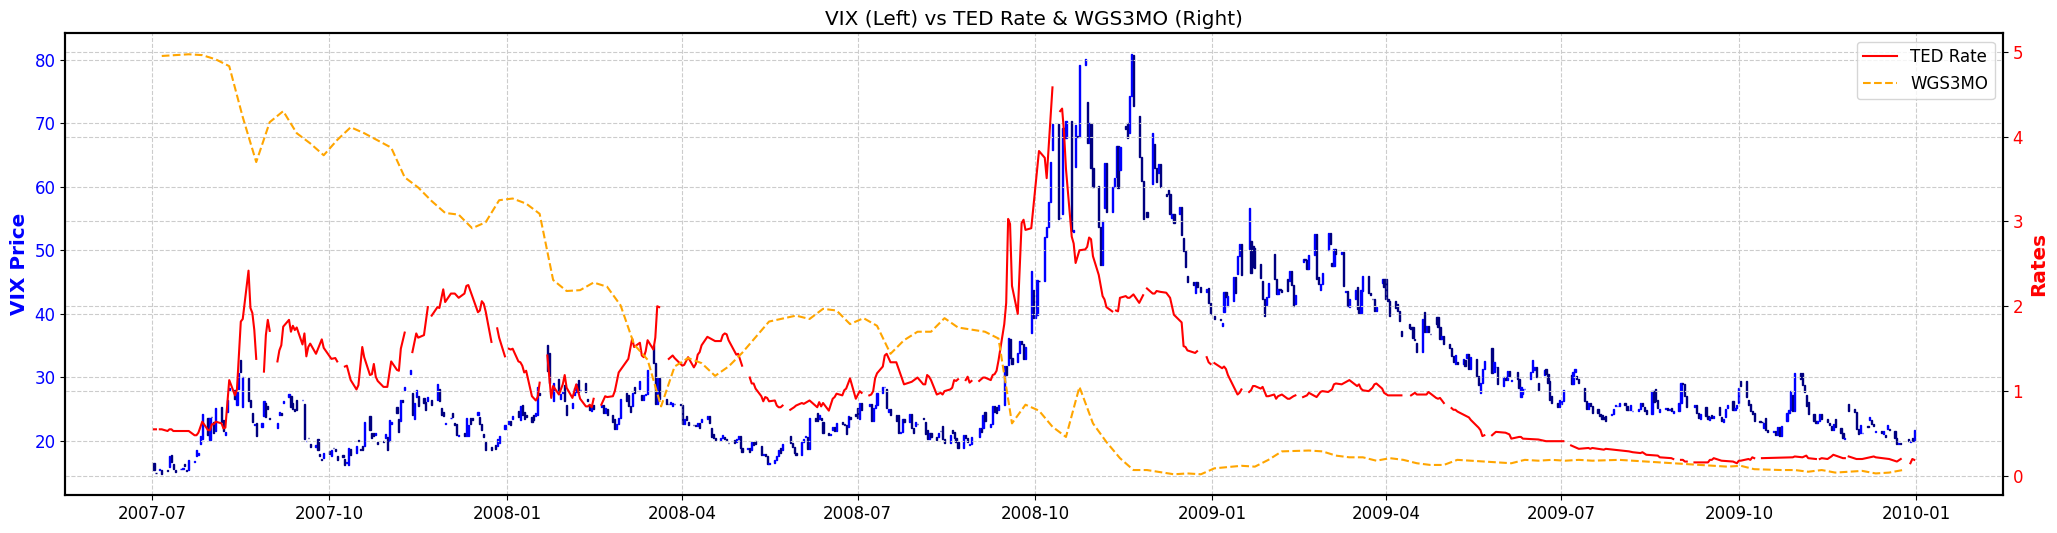

In [ ]:
# ===== PREPARE VIX =====
vix = _VIX.copy()
vix.set_index('Date', inplace=True)

vix['High'] = vix[['Open', 'Close']].max(axis=1)
vix['Low']  = vix[['Open', 'Close']].min(axis=1)

vix.reset_index(inplace=True)
vix['Date'] = pd.to_datetime(vix['Date'])
vix['DateNum'] = mdates.date2num(vix['Date'])

vix_ohlc = vix[['DateNum', 'Open', 'High', 'Low', 'Close']]


# ===== PREPARE TedRate =====
TedRate = TEDRATE.copy()

# Rename the existing 'TEDRATE' column to 'rate'
TedRate = TedRate.rename(columns={'TEDRATE': 'rate'})
TedRate["date"] = pd.to_datetime(TedRate.index, format="%Y-%m-%d")
TedRate.set_index("date", inplace=True)

# ===== PREPARE WGS3MO =====
wgs = WGS3MO.copy()

wgs.columns = ["date", "rate"]
wgs["date"] = pd.to_datetime(wgs["date"], format="%m/%d/%Y")
wgs.set_index("date", inplace=True)


# ===== APPLY COMMON DATE FILTER =====
start_date = "2007-07-01"

# VIX
vix = vix[vix['Date'] >= start_date]
vix_ohlc = vix[['DateNum', 'Open', 'High', 'Low', 'Close']]

# TED Rate
TedRate = TedRate[TedRate.index >= start_date]

# WGS3MO
wgs = wgs[wgs.index >= start_date]


fig, ax1 = plt.subplots(figsize=(25, 6))
# ----- LEFT AXIS = VIX -----
candlestick_ohlc(
    ax1,
    vix_ohlc.values,
    width=0.6,
    colorup='blue',
    colordown='navy'
)

ax1.set_ylabel("VIX Price", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')


# ----- RIGHT AXIS = TedRate + WGS3MO -----
ax2 = ax1.twinx()

ax2.plot(TedRate.index, TedRate["rate"],
         color='red', linewidth=1.5, label='TED Rate')

ax2.plot(wgs.index, wgs["rate"],
         color='orange', linewidth=1.5, linestyle='--', label='WGS3MO')

ax2.set_ylabel("Rates", color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax2.legend(loc='upper right')




# ----- Shared X settings -----
ax1.xaxis_date()
ax1.set_title("VIX (Left) vs TED Rate & WGS3MO (Right)")

plt.show()

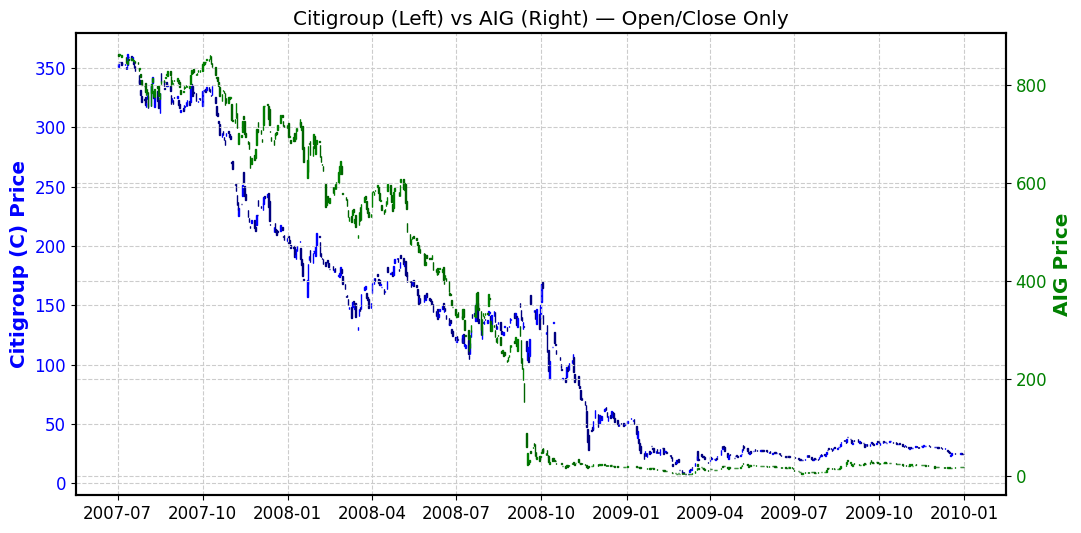

In [ ]:
# ==========================
# 1) PREPARE CITIGROUP (C)
# ==========================
c = C.copy()
c.set_index('Date', inplace=True)

# Remove wicks → open/close only
c['High'] = c[['Open', 'Close']].max(axis=1)
c['Low']  = c[['Open', 'Close']].min(axis=1)

c.reset_index(inplace=True)
c['Date'] = pd.to_datetime(c['Date'])
c['DateNum'] = mdates.date2num(c['Date'])




# ==========================
# 2) PREPARE AIG
# ==========================
aig = AIG.copy()
aig.set_index('Date', inplace=True)

aig['High'] = aig[['Open', 'Close']].max(axis=1)
aig['Low']  = aig[['Open', 'Close']].min(axis=1)

aig.reset_index(inplace=True)
aig['Date'] = pd.to_datetime(aig['Date'])
aig['DateNum'] = mdates.date2num(aig['Date'])

start_date = "2007-07-01"

c = c[c['Date'] >= start_date]
aig = aig[aig['Date'] >= start_date]

aig_ohlc = aig[['DateNum', 'Open', 'High', 'Low', 'Close']]
c_ohlc = c[['DateNum', 'Open', 'High', 'Low', 'Close']]

# ==========================
# 3) PLOT DUAL AXIS
# ==========================
fig, ax1 = plt.subplots(figsize=(12, 6))

# ----- LEFT AXIS = C -----
candlestick_ohlc(
    ax1,
    c_ohlc.values,
    width=0.6,
    colorup='blue',
    colordown='navy'
)

ax1.set_ylabel("Citigroup (C) Price", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')


# ----- RIGHT AXIS = AIG -----
ax2 = ax1.twinx()

candlestick_ohlc(
    ax2,
    aig_ohlc.values,
    width=0.6,
    colorup='green',
    colordown='darkgreen'
)

ax2.set_ylabel("AIG Price", color='green')
ax2.tick_params(axis='y', labelcolor='green')


# ----- Shared formatting -----
ax1.xaxis_date()
ax1.set_title("Citigroup (Left) vs AIG (Right) — Open/Close Only")

plt.show()
